# VD 11 — Finite lifted rough-kernel memory of native 5-minute volatility

**Branch:** `Volatility_Dynamics` (independent from HSMM, Hurst_Regimes, VRP, etc.)  
**Status:** prospective research experiment / **not** a signal, trading model or latent lifted-Heston calibration.

## Testable hypothesis

> Does a structured finite exponential approximation of a rough kernel explain **future q99 onset hazard** more usefully than a fixed-lag model, and more usefully than ordinary exponential memory?

The primitive is $v_t=r_t^2$ at native five-minute resolution. We use $y_t = \log(v_t+\epsilon_i)-C_i(\text{UTC-hour}_t)$ with **asset-specific training-only** $\epsilon_i$ and $C_i$.

A **strictly lagged** factor is

$$M_{j,t}=\rho_j M_{j,t-1}+(1-\rho_j)y_{t-1},\qquad
\rho_j=e^{-5\log(2)/\tau_j}.$$

Every factor is a causal, observed-weight-normalized EMA: missing observations contribute zero mass and are explicitly time-discounted, without return imputation. Origins require 288 elapsed prior five-minute slots, at least 80% observed history, and a past observed return within 15 minutes. The kernel is only **rough-inspired**: no latent Brownian innovations, no stochastic-variance state estimation, no physical/risk-neutral equivalence claim.

For $\alpha=H+\frac12\in(\frac12,1)$,

$$K_H(s)=\frac{s^{\alpha-1}}{\Gamma(\alpha)}\approx\sum_{j=1}^{N}w_j e^{-x_js},\quad w_j>0.$$

The $x_j$ grid is geometric in rates (roughly 8 minutes to 15 hours in half-lives for N=4–8). Positive weights integrate the Laplace density over geometric cells; the weighted stationary memory uses weights proportional to $w_j/x_j$. The approximation error is explicitly reported over 5–1440 minutes.

We do **not** fit each $M_j$ freely and claim to have estimated $H$: that would often make $H$ unidentifiable. The rough model uses **one kernel-weighted memory aggregate** plus a fast–slow contrast, so $H$ changes the shape of its constrained representation.

## Frozen comparisons and safeguards

| Model | Features added beyond asset and clock controls |
|---|---|
| **A — current** | De-clocked current five-minute log variance |
| **B — fixed lags** | Current plus 5, 10, 30, 60, 120-minute lag values |
| **E — two EMAs** | Current plus 30-minute and 4-hour exponential memories |
| **F — equal multiscale** | Current plus an equal-weight mean of exactly the same factor-rate grid as C, and a fast–slow contrast; independently selects N |
| **C — rough-inspired lift** | Current plus kernel-weighted memory and fast-minus-slow factor contrast |

Primary horizon: **60 minutes**. Auxiliary horizons: 30, 90, 120 minutes. Event: first bar of a run of per-asset $v_t$ exceeding the **training** 99th percentile. At origin $t$, the q99 bar at $t$ is excluded from eligible forecasts. $Y_h(t)=1$ if there is an onset in $(t,t+h]$; windows with missing future bars or crossing fit/validation/test boundaries are **censored**, not assigned zero.

Chronology: 60% UTC days training, 20% validation, 20% held-out test. Training estimates variance epsilon, clock medians, q99 thresholds, feature standardization and regression coefficients. **Validation chooses $H$, $N$, ridge regularization and model hyperparameters using 60m log loss only**; the test period is never used for tuning. Candidate grid: $H\in\{.05,.10,.20,.30,.40\}$, $N\in\{4,6,8\}$, ridge $\in\{10^{-4},10^{-3},10^{-2}\}$. No HMM fitting in Module 11.

The final comparison uses **identical observations** and a paired **UTC-day bootstrap**, retaining multi-asset synchrony. Require at least 20 independent q99 onset timestamps and 10 test days for a provisional passing claim. C must beat **both** B and F with negative paired mean log-loss differences and negative 97.5% bootstrap bounds to justify advancing the rough-specificity hypothesis. Anything short of that is null / inconclusive.

**No fitting to test data, no lookahead, no gap interpolation, no fixed -95-minute selection, no production export and no mutation of the DuckDB database.**

In [1]:
from pathlib import Path
import json, os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
import duckdb

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT/'src'/'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT/'src'/'data_engineering').exists(), 'Run inside deribit-market-data repository'
load_dotenv(PROJECT_ROOT/'.env')
SRC=PROJECT_ROOT/'src'
if str(SRC) not in sys.path: sys.path.insert(0,str(SRC))
from data_engineering.modeling import volatility_lifted_memory as lm

DATA_ROOT=Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
DB_PATH=DATA_ROOT/'database'/'research.duckdb'
assert DB_PATH.exists(), f'Research DB not found: {DB_PATH}'
OUT=PROJECT_ROOT/'notebooks'/'Volatility_Dynamics'/'11'
OUT.mkdir(parents=True, exist_ok=True)
ASSETS=[x.strip().upper() for x in os.getenv('VD11_ASSETS','').split(',') if x.strip()]
START=os.getenv('VD11_START','').strip()
END=os.getenv('VD11_END','').strip()
BOOT=int(os.getenv('VD11_BOOT','500'))
print('VD 11 | read-only DB:',DB_PATH, '| bootstrap reps:',BOOT)

VD 11 | read-only DB: D:\MarketData\Deribit\database\research.duckdb | bootstrap reps: 500


## 1. Read the narrow primitive panel

Only `state_time`, `underlying`, and `return_5m` are requested from `time_series_feature_state`. There is no option family switch, no L2 readiness gate, and no import of earlier research outputs.

In [2]:
query = 'SELECT state_time, underlying, return_5m FROM time_series_feature_state'
where=[]; args=[]
if START:
    where.append('state_time >= ?'); args.append(pd.Timestamp(START, tz='UTC') if pd.Timestamp(START).tzinfo is None else pd.Timestamp(START).tz_convert('UTC'))
if END:
    where.append('state_time < ?'); args.append(pd.Timestamp(END, tz='UTC') if pd.Timestamp(END).tzinfo is None else pd.Timestamp(END).tz_convert('UTC'))
if ASSETS:
    where.append('underlying IN ('+','.join(['?']*len(ASSETS))+')'); args.extend(ASSETS)
if where: query+=' WHERE '+' AND '.join(where)
query+=' ORDER BY underlying, state_time'
con=duckdb.connect(str(DB_PATH),read_only=True)
try: raw=con.execute(query,args).df()
finally: con.close()
if raw.empty: raise RuntimeError('No observations for selected filters')
print('rows',len(raw),'assets',list(raw.underlying.unique()),'min/max',raw.state_time.min(),raw.state_time.max())
panel=lm.dense_panel(raw)
panel, clock=lm.training_clock(panel)
labels, thresholds=lm.q99_labels(panel)
print('split ranges:')
display(panel.groupby('split',sort=False).agg(days=('date','nunique'),rows=('v','size'),finite=('v','count'),first=('state_time','min'),last=('state_time','max')))
display(thresholds)

rows 42336 assets ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP'] min/max 2026-09-19 10:00:00+02:00 2026-10-10 09:55:00+02:00
split ranges:


,days,rows,finite,first,last
split,,,,,
train,13,25536,20697,2026-09-19 08:00:00+00:00,2026-10-01 23:55:00+00:00
valid,4,8064,7770,2026-10-02 00:00:00+00:00,2026-10-05 23:55:00+00:00
test,5,8736,8365,2026-10-06 00:00:00+00:00,2026-10-10 07:55:00+00:00


,underlying,train_q99_threshold_v
0,AVAX,0.000118
1,BTC,0.000015
2,ETH,0.000021
3,HYPE,0.000048
4,SOL,0.000041
5,TRX,0.000003
6,XRP,0.000064


## 2. Construct B, E, F and C on a strictly common support

We require 288 consecutive finite five-minute observations (**24-hour warmup**) before allowing an origin. Missing intervals are inserted as NaNs on the native grid; they reset memory. This is conservative and maintains comparability across all candidates. Memory may continue causally across the 08:00 UTC option session boundary because the return series is perpetual futures, not the option chain.

In [3]:
frame=panel.join(labels[['q99','onset','eligible_now'] + [f'y_{h}m' for h in lm.HORIZONS]])
fixed=lm.fixed_lags(panel)
frame=frame.join(fixed)
E=lm.simple_exponential_features(panel)
frame=frame.join(E[['ema_30m','ema_240m']])
config={}
Fconfig={}
all_candidate_cols=[]
for N in lm.N_GRID:
    # EMA rates are identical for every H at fixed N: compute once.
    rates,_=lm.quadrature(.10,N)
    em=lm.ema_prior(panel, np.log(2)/rates)
    eq=lm.equal_exponential_features(panel,N,precomputed=em)
    e_key, s_key=f'f_n{N}_equal',f'f_n{N}_slope'
    frame[e_key]=eq.equal_memory
    frame[s_key]=eq.fast_minus_slow
    all_candidate_cols.extend([e_key,s_key])
    Fconfig[N]=[ 'now',e_key,s_key ]
    for H in lm.H_GRID:
        lifted, info=lm.lifted_features(panel,H,N,precomputed=em)
        tag=f'h{int(100*H):02d}_n{N}'
        k,s=f'{tag}_kernel',f'{tag}_slope'
        frame[k]=lifted.kernel_memory
        frame[s]=lifted.fast_minus_slow
        all_candidate_cols.extend([k,s])
        config[tag]=dict(info, kernel_column=k, slope_column=s)

specs={'A_current':['now'],
       'B_fixed':['now']+[f'lag_{k*5}m' for k in lm.LAG_BARS],
       'E_exponential':['now','ema_30m','ema_240m']}
core_cols=sorted(set(sum(specs.values(),[]) + all_candidate_cols))
history=lm.memory_diagnostics(panel)
mask=history.memory_ready.to_numpy(bool) & np.isfinite(frame[core_cols].to_numpy(float)).all(axis=1)
frame['eligible_now']=frame.eligible_now.to_numpy(bool) & mask
print('24h prior-history coverage / readiness by split (current and future gaps are NOT filled):')
display(panel[['split']].join(history).groupby('split').agg(
    history_coverage_median=('past_memory_coverage','median'),
    history_ready=('memory_ready','sum'),
    recent_input_ok=('recent_prior_observed','sum')))
print('Candidate feature origin support by split:')
display(frame.groupby('split').eligible_now.agg(['sum','size','mean']))
print('Kernel-relative shape errors (not fit criteria):')
display(pd.DataFrame([{'tag':k,'H':v['H'],'N':v['N'],
                       'kernel_error':v['kernel_relative_rms_error']} for k,v in config.items()])
        .sort_values('kernel_error').head(10))

24h prior-history coverage / readiness by split (current and future gaps are NOT filled):


,history_coverage_median,history_ready,recent_input_ok
split,,,
test,0.961806,8358,8729
train,0.972222,19066,21224
valid,0.965278,7756,8050


Candidate feature origin support by split:


,sum,size,mean
split,,,
test,6958,8736,0.796474
train,16928,25536,0.662907
valid,6852,8064,0.849702


Kernel-relative shape errors (not fit criteria):


,tag,H,N,kernel_error
10,h05_n8,0.05,8,0.295632
5,h05_n6,0.05,6,0.296175
0,h05_n4,0.05,4,0.297844
11,h10_n8,0.10,8,0.317264
6,h10_n6,0.10,6,0.317864
1,h10_n4,0.10,4,0.319661
12,h20_n8,0.20,8,0.359074
7,h20_n6,0.20,6,0.359761
2,h20_n4,0.20,4,0.361761
13,h30_n8,0.30,8,0.398239


## 3. Choose all hyperparameters on validation only

The grid is pre-declared; 60m validation log loss determines a single C configuration and an independent F factor-count configuration. This is **not** evidence that the fitted $H$ is a structural Hurst exponent. A predictive preference across kernel shapes is all we can claim. B/E/A ridge values are also selected on validation at the same 60m horizon.

In [4]:
selection=[]
for model,names in specs.items():
    for lam in lm.RIDGE_GRID:
        try:
            metrics,_=lm.fit_predict(frame,names,lam,lm.PRIMARY_HORIZON,eval_split='valid')
            selection.append(dict(model=model, ridge=lam, H=np.nan,N=np.nan,tag='', **metrics))
        except ValueError as exc:
            raise RuntimeError(f'{model} validation failed: {exc}') from exc
for N,names in Fconfig.items():
    for lam in lm.RIDGE_GRID:
        metrics,_=lm.fit_predict(frame,names,lam,lm.PRIMARY_HORIZON,eval_split='valid')
        selection.append(dict(model='F_equal_multiscale',ridge=lam,H=np.nan,N=N,tag=f'f_n{N}',**metrics))
for tag, meta in config.items():
    names=['now',meta['kernel_column'],meta['slope_column']]
    for lam in lm.RIDGE_GRID:
        metrics,_=lm.fit_predict(frame,names,lam,lm.PRIMARY_HORIZON,eval_split='valid')
        selection.append(dict(model='C_lifted',ridge=lam,H=meta['H'],N=meta['N'],tag=tag,**metrics))
selection=pd.DataFrame(selection)
chosen=(selection.sort_values(['logloss','ridge']).groupby('model',sort=False).head(1)
         .set_index('model'))
selection.to_csv(OUT/'11_validation_grid.csv',index=False,float_format='%.8g')
display(chosen[['ridge','H','N','tag','logloss','brier','positive_origin_count','n_origins']])
chosen_tag=str(chosen.loc['C_lifted','tag'])
chosen_info=config[chosen_tag]
chosen_specs={**specs,'F_equal_multiscale':Fconfig[int(chosen.loc['F_equal_multiscale','N'])],'C_lifted':['now',chosen_info['kernel_column'],chosen_info['slope_column']]}

,ridge,H,N,tag,logloss,brier,positive_origin_count,n_origins
model,,,,,,,,
C_lifted,0.010,0.05,6.0,h05_n6,0.144613,0.034987,226,5972
F_equal_multiscale,0.001,NaN,4.0,f_n4,0.144639,0.035181,226,5972
E_exponential,0.010,NaN,NaN,,0.144849,0.035151,226,5972
B_fixed,0.010,NaN,NaN,,0.159988,0.036848,226,5972
A_current,0.010,NaN,NaN,,0.177233,0.039322,226,5972


## 4. Score the untouched test period (four horizons)

All four models use the same train rows, test rows, outcome definition and calendar support for each horizon. The actual test score can be unfavorable; do not change the candidate grid based on it.

In [5]:
rows=[]; predictions={}
for h in lm.HORIZONS:
    for model,names in chosen_specs.items():
        lam=float(chosen.loc[model,'ridge'])
        metrics,preds=lm.fit_predict(frame,names,lam,h,eval_split='test')
        rows.append({'horizon_min':h,'model':model,**metrics})
        predictions[h,model]=preds
scores=pd.DataFrame(rows)
scores.to_csv(OUT/'11_test_scores.csv',index=False,float_format='%.9g')
display(scores.pivot(index='horizon_min',columns='model',values='logloss').round(6))
print('Positive origin counts are overlapping labels, NOT independent shock counts.')
display(scores[['horizon_min','model','n_origins','positive_origin_count']])

model,A_current,B_fixed,C_lifted,E_exponential,F_equal_multiscale
horizon_min,,,,,
30,0.124490,0.120256,0.117751,0.117409,0.118927
60,0.210482,0.205013,0.201194,0.201094,0.204168
90,0.286106,0.280520,0.279380,0.280463,0.284626
120,0.354993,0.351054,0.353073,0.355421,0.360233


Positive origin counts are overlapping labels, NOT independent shock counts.


,horizon_min,model,n_origins,positive_origin_count
0,30,A_current,6103,159
1,30,B_fixed,6103,159
2,30,E_exponential,6103,159
3,30,F_equal_multiscale,6103,159
4,30,C_lifted,6103,159
5,60,A_current,5312,272
6,60,B_fixed,5312,272
7,60,E_exponential,5312,272
8,60,F_equal_multiscale,5312,272
9,60,C_lifted,5312,272


## 5. Paired daily-bootstrap comparisons

C minus B tests the value of rough-inspired state geometry against arbitrary finite lags. C minus F tests whether the rough-specific weighting beats equal-weight multiscale exponential memory at comparable rate scales. Correlated five-minute origins are not treated as independent draws in the uncertainty calculation.

In [6]:
comparisons=[]
for h in lm.HORIZONS:
    for contender in ('B_fixed','F_equal_multiscale','E_exponential','A_current'):
        pair=lm.align_comparison(predictions[h,'C_lifted'],predictions[h,contender])
        boot=lm.bootstrap_day_diff(pair,B=BOOT,seed=1105+h)
        comparisons.append({'horizon_min':h,'comparison':f'C_lifted - {contender}',
                            'n_paired_origins':len(pair),**boot})
boot_scores=pd.DataFrame(comparisons)
boot_scores.to_csv(OUT/'11_day_bootstrap.csv',index=False,float_format='%.9g')
display(boot_scores.round(6))

,horizon_min,comparison,n_paired_origins,delta_logloss,bootstrap_q025,bootstrap_q975,test_day_count
0,30,C_lifted - B_fixed,6103,-0.002505,-0.007405,0.002283,5
1,30,C_lifted - F_equal_multiscale,6103,-0.001175,-0.006198,0.003038,5
2,30,C_lifted - E_exponential,6103,0.000342,-0.000813,0.001516,5
3,30,C_lifted - A_current,6103,-0.006738,-0.013152,0.002206,5
4,60,C_lifted - B_fixed,5312,-0.003819,-0.014079,0.005984,5
5,60,C_lifted - F_equal_multiscale,5312,-0.002974,-0.010092,0.003001,5
6,60,C_lifted - E_exponential,5312,0.000100,-0.001793,0.001955,5
7,60,C_lifted - A_current,5312,-0.009288,-0.024232,0.008561,5
8,90,C_lifted - B_fixed,4703,-0.001139,-0.019601,0.019262,5
9,90,C_lifted - F_equal_multiscale,4703,-0.005245,-0.015094,0.003189,5


## 6. Decision gate (60-minute primary)

A PASS requires (i) at least 20 *unique* test onset timestamps, (ii) at least 10 independent UTC test days, and (iii) negative bootstrap 97.5% bounds for **both C − B and C − F**. It cannot be upgraded retroactively using auxiliary horizons or event-aligned figures. A negative log-loss improvement with too little test history is **INSUFFICIENT_DATA**, not proof.

In [7]:
n_unique_test_onsets=labels.loc[(labels.split=='test') & labels.onset & mask,'state_time'].nunique()
primary=boot_scores[boot_scores.horizon_min==lm.PRIMARY_HORIZON]
pb=primary[primary.comparison=='C_lifted - B_fixed'].iloc[0]
pf=primary[primary.comparison=='C_lifted - F_equal_multiscale'].iloc[0]
if n_unique_test_onsets < 20 or min(int(pb.test_day_count),int(pf.test_day_count)) < 10:
    verdict='INSUFFICIENT_DATA'
elif pb.delta_logloss < 0 and pb.bootstrap_q975 < 0 and pf.delta_logloss < 0 and pf.bootstrap_q975 < 0:
    verdict='PASS_INCREMENTAL_ROUGH_MEMORY'
elif pb.delta_logloss < 0 and pb.bootstrap_q975 < 0:
    verdict='NO_ROUGH_SPECIFICITY_VS_EQUAL_MULTISCALE'
else:
    verdict='NO_SUPPORTED_GAIN_VS_FIXED_LAGS'
decision={'status':verdict,'primary_horizon_min':60,'n_unique_test_onset_times':int(n_unique_test_onsets),
          'n_test_days':int(pb.test_day_count), 'rule':'C must improve versus both B and F with paired day-bootstrap upper 97.5% bound < 0; >=20 unique test onsets; >=10 UTC test days',
          'selected_tag':chosen_tag,'selected_H':float(chosen_info['H']),'selected_N':int(chosen_info['N'])}
print(json.dumps(decision,indent=2))
(OUT/'11_decision.json').write_text(json.dumps(decision,indent=2)+'\n',encoding='utf-8')

{
  "status": "INSUFFICIENT_DATA",
  "primary_horizon_min": 60,
  "n_unique_test_onset_times": 15,
  "n_test_days": 5,
  "rule": "C must improve versus both B and F with paired day-bootstrap upper 97.5% bound < 0; >=20 unique test onsets; >=10 UTC test days",
  "selected_tag": "h05_n6",
  "selected_H": 0.05,
  "selected_N": 6
}


330

## 7. Interpretable factor geometry and −95-minute diagnostics (descriptive only)

The following figures are examined **after** scoring. A trough or inflection around −95 minutes is not a prospective hypothesis test. The user-discovered motif was selected from earlier data, so a fresh, explicitly frozen study would be required to validate it.

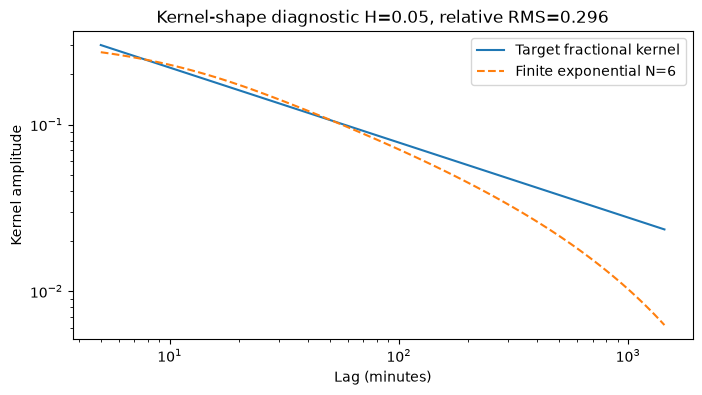

Effective half-lives in minutes: [  8.   20.6  52.9 136.  349.6 898.3]
Normalized kernel masses: [0.032 0.053 0.089 0.15  0.252 0.424]


In [8]:
rates,weights=lm.quadrature(chosen_info['H'],chosen_info['N'])
err,t,k_true,k_approx=lm.kernel_error(chosen_info['H'],rates,weights)
fig,ax=plt.subplots(figsize=(8,4))
ax.loglog(t,k_true,label='Target fractional kernel')
ax.loglog(t,k_approx,'--',label=f'Finite exponential N={chosen_info["N"]}')
ax.set(xlabel='Lag (minutes)',ylabel='Kernel amplitude',title=f'Kernel-shape diagnostic H={chosen_info["H"]:.2f}, relative RMS={err:.3f}')
ax.legend(); plt.show()
print('Effective half-lives in minutes:',np.round(chosen_info['half_lives_min'],1))
print('Normalized kernel masses:',np.round(chosen_info['memory_mass_weights'],3))

,relative_min,mean_factor,n_event_instances,n_unique_event_times
0,-120,0.511860,37.0,18.0
1,-115,0.292912,37.0,18.0
2,-110,0.268071,37.0,18.0
3,-105,0.136630,37.0,18.0
4,-100,0.060365,37.0,18.0
5,-95,0.076728,37.0,18.0
6,-90,0.128751,37.0,18.0
7,-85,0.032915,37.0,18.0
8,-80,0.119459,37.0,18.0
9,-75,-0.182657,37.0,18.0


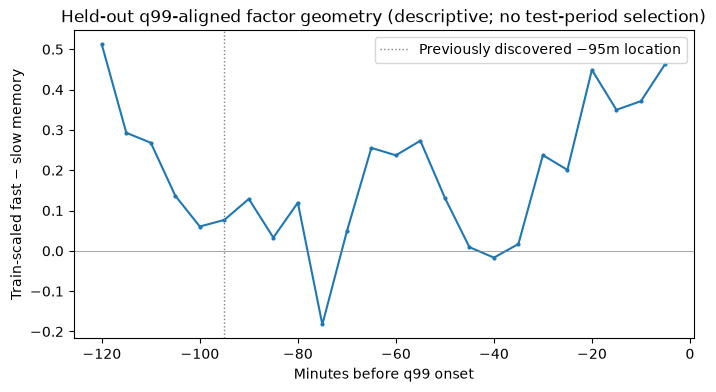

In [9]:
factor=frame[chosen_info['slope_column']].copy()
# Standardize solely for cross-asset visualization; fit per-asset center/scale on train only.
for asset, g in frame.groupby('underlying',sort=False):
    train_vals=factor.loc[g.index[g.split=='train']].dropna().to_numpy(float)
    center=float(np.median(train_vals))
    scale=float(np.std(train_vals)) if len(train_vals)>1 else 1.
    if scale <= 1e-10: scale=1.
    factor.loc[g.index]=(factor.loc[g.index]-center)/scale
alignment=lm.event_factor_path(panel,labels,factor)
if len(alignment):
    display(alignment[(alignment.relative_min >= -120) & (alignment.relative_min <= -5)])
    fig,ax=plt.subplots(figsize=(8,4))
    ax.plot(alignment.relative_min,alignment.mean_factor,marker='.',markersize=4)
    ax.axvline(-95,color='gray',linestyle=':',linewidth=1,label='Previously discovered −95m location')
    ax.axhline(0,color='gray',linewidth=.5)
    ax.set(xlabel='Minutes before q99 onset',ylabel='Train-scaled fast − slow memory',
           title='Held-out q99-aligned factor geometry (descriptive; no test-period selection)')
    ax.legend();plt.show()
else:
    print('No complete event paths in held-out test; alignment unavailable.')

## 8. Minimal run manifest and follow-up policy

Retain only small reproducible outputs: a validation grid, model-level test scores, bootstrap comparisons and a JSON decision/manifest. Factor arrays, full prediction tables, plot images and raw intermediate matrices are **not** exported.

**Interpretation:** A PASS here would warrant a *separate* future module testing incremental IV/activity/L2 information; only later, with sufficiently stable evidence, would the HMM/HSMM comparison be justified. A FAIL does not prove that volatility lacks memory, only that this constrained representation did not improve the specified held-out q99 task. No research output is automatically promoted to the trading pipeline.

In [10]:
manifest={'module':'Volatility_Dynamics_11','research_type':'rough-kernel-inspired-observable-memory',
          'source':'time_series_feature_state(state_time, underlying, return_5m)',
          'source_read_only':True,'start':str(panel.state_time.min()),'end':str(panel.state_time.max()),
          'n_original':int(len(raw)),'n_dense':int(len(panel)),
          'n_assets':int(panel.underlying.nunique()),
          'split_first_last':{s:{'start':str(d.state_time.min()),'end':str(d.state_time.max()),
                                 'rows':len(d),'days':int(d.date.nunique())}
                              for s,d in panel.groupby('split')},
          'n_common_valid_origins':int(frame.loc[(frame.split=='valid') & frame.eligible_now].shape[0]),
          'n_common_test_origins':int(frame.loc[(frame.split=='test') & frame.eligible_now].shape[0]),
          'epsilon_clock_train_only':True,'train_q99_thresholds':dict(zip(thresholds.underlying,thresholds.train_q99_threshold_v)),
          'selection':{m:{'ridge':float(r.ridge),'H':None if pd.isna(r.H) else float(r.H),
                           'N':None if pd.isna(r.N) else int(r.N),'tag':str(r.tag)}
                       for m,r in chosen.reset_index().set_index('model').iterrows()},
          'chosen_kernel':chosen_info,'decision':decision,
          'caveats':['Observed-return EMA factors are not inferred lifted-Heston stochastic latent factors',
                     'H selected for forecast validation; not a consistent structural roughness estimator',
                     'Finite factor grid has material truncation/initialization error',
                     'No option surface or L2 used; no cross-branch model import',
                     'Event-aligned figures are descriptive only']}
(OUT/'11_run_manifest.json').write_text(json.dumps(manifest,indent=2,default=str)+'\n',encoding='utf-8')
print('Compact files written to',OUT)
print('Scientific verdict:',decision['status'])

Compact files written to D:\Projects\deribit_market_data\notebooks\Volatility_Dynamics\11
Scientific verdict: INSUFFICIENT_DATA
